# Demonstrate:
- yahoo finance
- moving averages
- log scale
- differencing
- seasonal effects

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
# this magic to make pyplot interactive (zooming)
%matplotlib widget

In [2]:
symbol="AAPL"
stock = yf.Ticker(symbol)

# by default, adjusts for dividends and splits
df = stock.history(period="max")

df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-10-15 00:00:00-04:00,346.950012,347.850006,341.600006,342.000000,39767300,0.0,0.0
2026-10-16 00:00:00-04:00,346.089996,347.820007,340.459991,343.459991,59946400,0.0,0.0
2026-10-19 00:00:00-04:00,340.779999,346.000000,340.119995,342.940002,34573200,0.0,0.0
2026-10-20 00:00:00-04:00,339.859985,343.059998,338.700012,339.500000,35851400,0.0,0.0
2026-10-21 00:00:00-04:00,339.359985,345.250000,338.829987,343.989990,35577700,0.0,0.0


In [3]:
sma_lag=50
df["SMA"] = df["Close"].rolling(window=sma_lag).mean()
ema_lag=250
df["EMA"] = df["Close"].ewm(span=ema_lag, adjust=False).mean()

df.head(52)


,Open,High,Low,Close,Volume,Dividends,Stock Splits,SMA,EMA
Date,,,,,,,,,
1980-12-12 00:00:00-05:00,0.098122,0.098549,0.098122,0.098122,469033600,0.0,0.0,NaN,0.098122
1980-12-15 00:00:00-05:00,0.093430,0.093430,0.093003,0.093003,175884800,0.0,0.0,NaN,0.098082
1980-12-16 00:00:00-05:00,0.086604,0.086604,0.086177,0.086177,105728000,0.0,0.0,NaN,0.097987
1980-12-17 00:00:00-05:00,0.088310,0.088737,0.088310,0.088310,86441600,0.0,0.0,NaN,0.097910
1980-12-18 00:00:00-05:00,0.090870,0.091297,0.090870,0.090870,73449600,0.0,0.0,NaN,0.097854
1980-12-19 00:00:00-05:00,0.096416,0.096843,0.096416,0.096416,48630400,0.0,0.0,NaN,0.097842
1980-12-22 00:00:00-05:00,0.101109,0.101536,0.101109,0.101109,37363200,0.0,0.0,NaN,0.097868
1980-12-23 00:00:00-05:00,0.105375,0.105802,0.105375,0.105375,46950400,0.0,0.0,NaN,0.097928
1980-12-24 00:00:00-05:00,0.110921,0.111348,0.110921,0.110921,48003200,0.0,0.0,NaN,0.098031


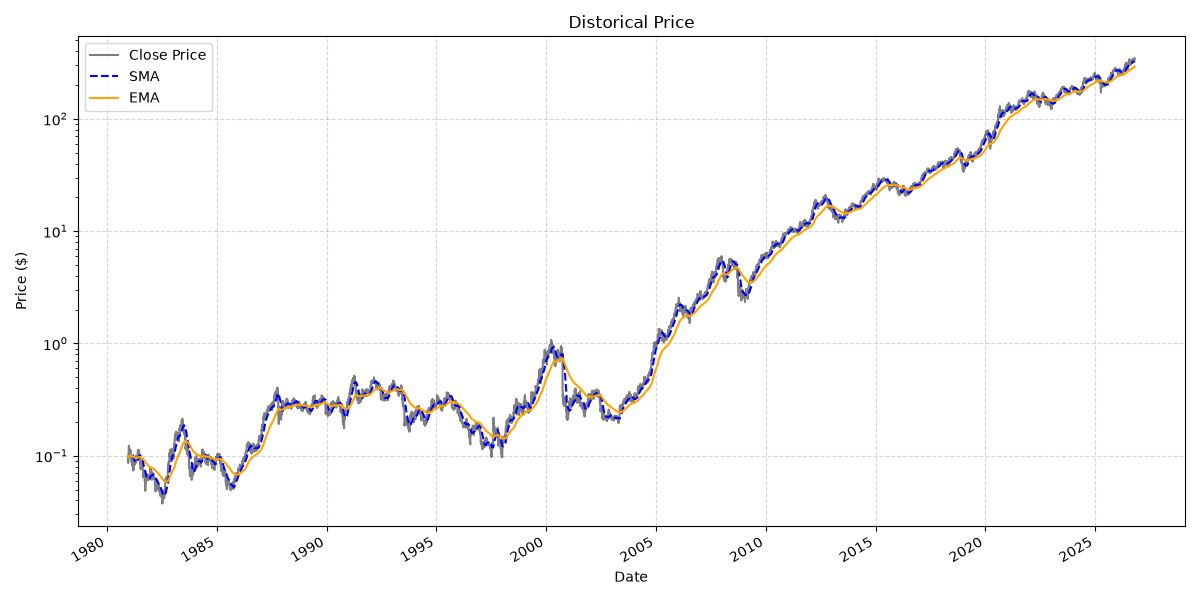

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

df["Close"].plot(
    ax=ax, 
    logy=True, 
    label="Close Price", 
    color="black", 
    alpha=0.5)

df["SMA"].plot(
    ax=ax,
    logy=True,
    label="SMA",
    color="blue",
    linestyle="--",
    linewidth=1.5,
)
df["EMA"].plot(
    ax=ax,
    logy=True,
    label="EMA",
    color="orange",
    linestyle="-",
    linewidth=1.5,
)

plt.title("Distorical Price")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
df["Price_Diff"] = df["Close"].diff()
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# 3. Extract Time Features
df["Month"] = df.index.month_name()
df["Day_of_Week"] = df.index.day_name()

# Sort order for categorical plotting
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

# Drop initial NaN from differencing
df_clean = df.dropna()
df_clean.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,SMA,EMA,Price_Diff,Log_Return,Month,Day_of_Week
Date,,,,,,,,,,,,,
2026-10-15 00:00:00-04:00,346.950012,347.850006,341.600006,342.000000,39767300,0.0,0.0,325.067617,290.575112,-0.959991,-0.002803,October,Thursday
2026-10-16 00:00:00-04:00,346.089996,347.820007,340.459991,343.459991,59946400,0.0,0.0,325.694000,290.996506,1.459991,0.004260,October,Friday
2026-10-19 00:00:00-04:00,340.779999,346.000000,340.119995,342.940002,34573200,0.0,0.0,326.291600,291.410398,-0.519989,-0.001515,October,Monday
2026-10-20 00:00:00-04:00,339.859985,343.059998,338.700012,339.500000,35851400,0.0,0.0,326.916400,291.793582,-3.440002,-0.010082,October,Tuesday
2026-10-21 00:00:00-04:00,339.359985,345.250000,338.829987,343.989990,35577700,0.0,0.0,327.698000,292.209490,4.489990,0.013139,October,Wednesday


In [6]:
# averages by month
monthly_summary = (
    df.groupby(df.index.month_name())["Log_Return"]
    .agg(["mean", "std"])
    .reindex(month_order)
)
monthly_summary.columns = [
    "Mean Log Return",
    "Std Dev",
]

# averages by day of the week
daily_summary = (
    df.groupby(df.index.day_name())["Log_Return"]
    .agg(["mean","std"])
    .reindex(day_order)
)
daily_summary.columns = [
    "Mean Log Return",
    "Std Dev",
]

# roughly 252 trading days per year
monthly_summary["Annualized Mean"] = (
    monthly_summary["Mean Log Return"] * 252
)
monthly_summary["Annualized Std Dev"] = (
    monthly_summary["Std Dev"] * np.sqrt(252)
)

daily_summary["Annualized Mean"] = (
    daily_summary["Mean Log Return"] * 252
)
daily_summary["Annualized Std Dev"] = (
    daily_summary["Std Dev"] * np.sqrt(252)
)


# Display simple formatted tables
print("=== AVERAGE LOG RETURN BY MONTH ===")
print(monthly_summary.to_string(formatters={"Mean Log Return": "{:.5f}".format}))

print("\n=== AVERAGE LOG RETURN BY DAY OF WEEK ===")
print(daily_summary.to_string(formatters={"Mean Log Return": "{:.5f}".format}))

=== AVERAGE LOG RETURN BY MONTH ===
          Mean Log Return   Std Dev  Annualized Mean  Annualized Std Dev
Date                                                                    
January           0.00121  0.031895         0.305720            0.506321
February          0.00062  0.023406         0.156057            0.371558
March             0.00077  0.026505         0.193633            0.420753
April             0.00147  0.026863         0.370126            0.426434
May               0.00084  0.023829         0.210658            0.378279
June             -0.00127  0.023468        -0.319997            0.372537
July              0.00112  0.029362         0.283371            0.466114
August            0.00213  0.025287         0.536318            0.401411
September        -0.00253  0.036866        -0.637777            0.585232
October           0.00228  0.032967         0.573791            0.523342
November          0.00111  0.025910         0.280251            0.411311
December       

In [7]:
import statsmodels.api as sm

month_dummies = pd.get_dummies(
    df_clean.index.month_name(), drop_first=True
).astype(int)
month_dummies.index = df_clean.index

X = sm.add_constant(
    month_dummies
)  # The constant (intercept) represents April
y = df_clean["Log_Return"]

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             Log_Return   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     2.314
Date:                Thu, 22 Oct 2026   Prob (F-statistic):            0.00788
Time:                        13:18:46   Log-Likelihood:                 24899.
No. Observations:               11508   AIC:                        -4.977e+04
Df Residuals:                   11496   BIC:                        -4.969e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0015      0.001      1.628      0.1

In [8]:
# note: look up Bonferroni correction